In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Una obra de edificación necesita suministro eléctrico provisional. El cuadro de prelaciones, las duraciones (semanas) y la potencia eléctrica que demanda cada actividad (`kW`, grúa, hormigonera, soldadura, bombas, secado) se adjuntan; se trabaja 40 horas por semana a plena potencia.

In [4]:
#| tbl-cap: "Cuadro de datos del enunciado"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration, kW
    ('A'     , '---'      , 6       , 20),
    ('B'     , '---'      , 3       , 25),
    ('C'     , 'B'        , 6       , 15),
    ('D'     , 'B'        , 1       , 30),
    ('E'     , 'C'        , 5       , 30),
    ('F'     , 'A,D'      , 2       , 25),
    ('G'     , 'D,E'      , 2       , 25),
    ('H'     , 'F'        , 2       , 15),
    ('I'     , 'G,H'      , 4       , 10),
], columns=['activity', 'predecessor', 'duration', 'kW']).set_index('activity')
datos_enunciado

,predecessor,duration,kW
activity,,,
A,---,6,20
B,---,3,25
C,B,6,15
D,B,1,30
E,C,5,30
F,"A,D",2,25
G,"D,E",2,25
H,F,2,15
I,"G,H",4,10


Opciones: un **grupo electrógeno** de gasóleo dimensionado para el pico de demanda (alquiler 0.8 k€ por semana, consumo 0.3 l por kWh, gasóleo a 1.3 €/l, factor 2.47 kg CO₂ por litro) o una **acometida provisional** de la compañía, que ofrece hasta **45 kW** por 8 k€ y tarda 5 semanas en estar disponible (electricidad a 0.18 €/kWh, factor 0.15 kg CO₂ por kWh). La organización aplica un precio sombra del carbono de 250 €/t.

> **De: Jefe de obra**
> Grupo electrógeno para toda la obra y nos olvidamos de la compañía: con inicios más tempranos el pico es de 65 kW, más de los 45 que dan, y la acometida no llega hasta la semana 5. Se alquila uno grande y punto; el gasóleo va a costes generales.

## Criterio de referencia

Las preguntas del bloque **B** se responden aplicando los criterios siguientes, tomados de la lección 20 (redactados por el curso; cada uno remite a la fuente de la que procede, que no se reproduce). La respuesta se justifica citando el criterio y la fuente, no con una opinión.

- **S2 — Externalidad internalizada.** Cuando la organización ha fijado un precio para una externalidad (precio sombra del carbono, canon, tasa), toda decisión de planificación —comprimir, comprar, diseñar— se compara por el coste total: coste del proyecto más el valor de la externalidad a ese precio. Con el precio fijado, la alternativa correcta es la de menor coste total, y comprar compensaciones a un precio inferior no cambia la cuenta. *(cf. PMBOK 8 §3.7 (estrategias para abordar las externalidades); LCSP art. 148.2 (externalidades medioambientales monetizables); precio sombra del carbono del BEI.)*
- **S1 — Jerarquía de respuesta a los impactos (pirámide de sostenibilidad).** Ante un impacto negativo del proyecto las estrategias se ordenan de menos a más deseable: compensar o contrarrestar el daño, restaurarlo, minimizarlo y evitarlo. Compensar cuando se podía minimizar o evitar es quedarse en el escalón más bajo; clasificar una propuesta en su escalón es una pregunta con respuesta única. *(cf. PMBOK 8, principio «integrar la sostenibilidad en todas las áreas del proyecto» (§3.7, figura 3-7).)*
- **S6 — Alcances de las emisiones.** Las emisiones de un proyecto se clasifican por quién controla la fuente: alcance 1, combustión en fuentes propias o controladas (maquinaria y vehículos propios, generadores); alcance 2, electricidad comprada; alcance 3, el resto de la cadena (subcontratas, transporte ajeno, materiales comprados, viajes). A qué alcance pertenece cada fuente tiene respuesta determinada, y el alcance 3 no deja de contar por ser ajeno. *(cf. GHG Protocol, estándar corporativo; UNE-EN ISO 14064-1; registro de huella de carbono del MITECO (RD 163/2014).)*
- **Norma o dato de referencia — factores de emisión que usa el enunciado: gasóleo 2,47 kg CO₂ por litro; electricidad de red 0,15 kg CO₂ por kWh (mix de comercializadora genérico); transporte por carretera 0,10 y marítimo 0,015 kg CO₂ por tonelada y kilómetro. Son valores orientativos: en un caso real se toman los factores oficiales del año** *(calculadora de huella de carbono del MITECO (factores anuales); CNMC (mix de comercializadoras).)*
- **Norma o dato de referencia — alcance 1: emisiones directas de fuentes propias o controladas (combustible de maquinaria y vehículos propios, generadores en obra); alcance 2: emisiones indirectas de la electricidad comprada; alcance 3: las demás emisiones indirectas de la cadena de valor (materiales comprados, transporte contratado, subcontratas, residuos, viajes)** *(GHG Protocol, Corporate Accounting and Reporting Standard; UNE-EN ISO 14064-1.)*

Responda a las preguntas: A (cálculo), B (criterio) y C (deliberación).

In [5]:
pregunta_1 = "1. (A) Dibuje el diagrama de cargas eléctricas con inicios más tempranos y obtenga el pico. Nivele las cargas dentro de las holguras y compruebe si el pico nivelado cabe en los 45 kW de la acometida sin alargar el proyecto. Calcule la energía total de la obra (kWh).  "
pregunta_2 = "2. (A) Calcule el coste y las emisiones de las dos opciones: grupo electrógeno toda la obra, y grupo durante las 5 primeras semanas y acometida después (con las cargas niveladas). Compare el coste total al precio sombra.  "
pregunta_3 = "3. (B) Según los criterios de referencia, ¿qué opción es la correcta y en qué escalón de la pirámide está cada una? ¿A qué alcance pertenecen las emisiones del grupo electrógeno y las de la acometida?  "
pregunta_4 = "4. (C) ¿Qué propone al jefe de obra? Aplique la rúbrica de la lección.  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. (A) Dibuje el diagrama de cargas eléctricas con inicios más tempranos y obtenga el pico. Nivele las cargas dentro de las holguras y compruebe si el pico nivelado cabe en los 45 kW de la acometida sin alargar el proyecto. Calcule la energía total de la obra (kWh).  

2. (A) Calcule el coste y las emisiones de las dos opciones: grupo electrógeno toda la obra, y grupo durante las 5 primeras semanas y acometida después (con las cargas niveladas). Compare el coste total al precio sombra.  

3. (B) Según los criterios de referencia, ¿qué opción es la correcta y en qué escalón de la pirámide está cada una? ¿A qué alcance pertenecen las emisiones del grupo electrógeno y las de la acometida?  

4. (C) ¿Qué propone al jefe de obra? Aplique la rúbrica de la lección.  

# Resolución

In [6]:
capacidad_acometida, plazo_acometida, alquiler_grupo, coste_acometida, precio_sombra = 45, 5, 0.8, 8, 250
consumo_grupo, precio_gasoleo, precio_red, factor_gasoleo, factor_red, horas_semana = 0.3, 1.3, 0.18, 2.47, 0.15, 40
datos_proyecto = datos_enunciado.copy()
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
calendario = proyecto.calendar(datos_proyecto['duration'])
duracion = int(proyecto.duration(datos_proyecto['duration']))

Cálculo de los tiempos tempranos y tardíos de los sucesos y de las holguras totales paso a paso. El primer paso muestra el grafo resuelto; a partir del siguiente se calcula desde el principio (avance con los botones):

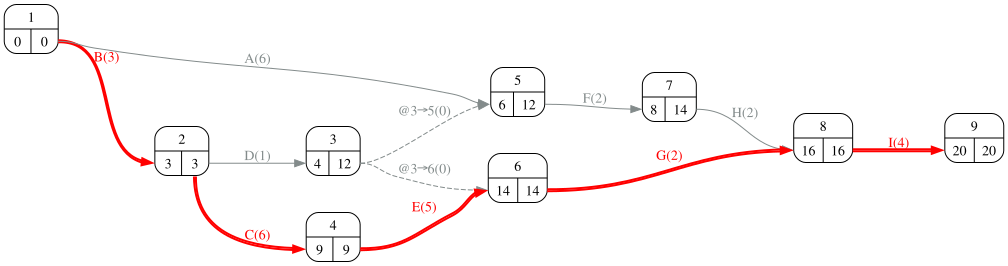

In [8]:
#| fig-cap: "Grafo PERT del proyecto"
#| label: fig-pert
proyecto.display_pert_pasos(datos_proyecto['duration'])

## Apartado 1

In [9]:
display(Markdown(pregunta_1))

1. (A) Dibuje el diagrama de cargas eléctricas con inicios más tempranos y obtenga el pico. Nivele las cargas dentro de las holguras y compruebe si el pico nivelado cabe en los 45 kW de la acometida sin alargar el proyecto. Calcule la energía total de la obra (kWh).  

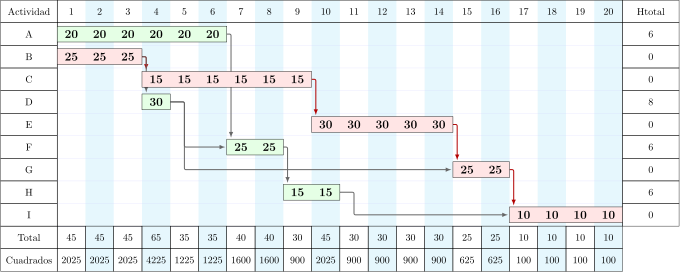

In [10]:
#| fig-cap: "Gantt con inicios más tempranos y demanda eléctrica (kW)"
#| label: fig-ganttCargas
gantt_inicial, dibujo = proyecto.copy().gantt_cargas(datos_proyecto.copy(), 'duration', 'kW', report=False, tikz=True, params=GANTT_PARAMS)
pinta_tikz(dibujo)

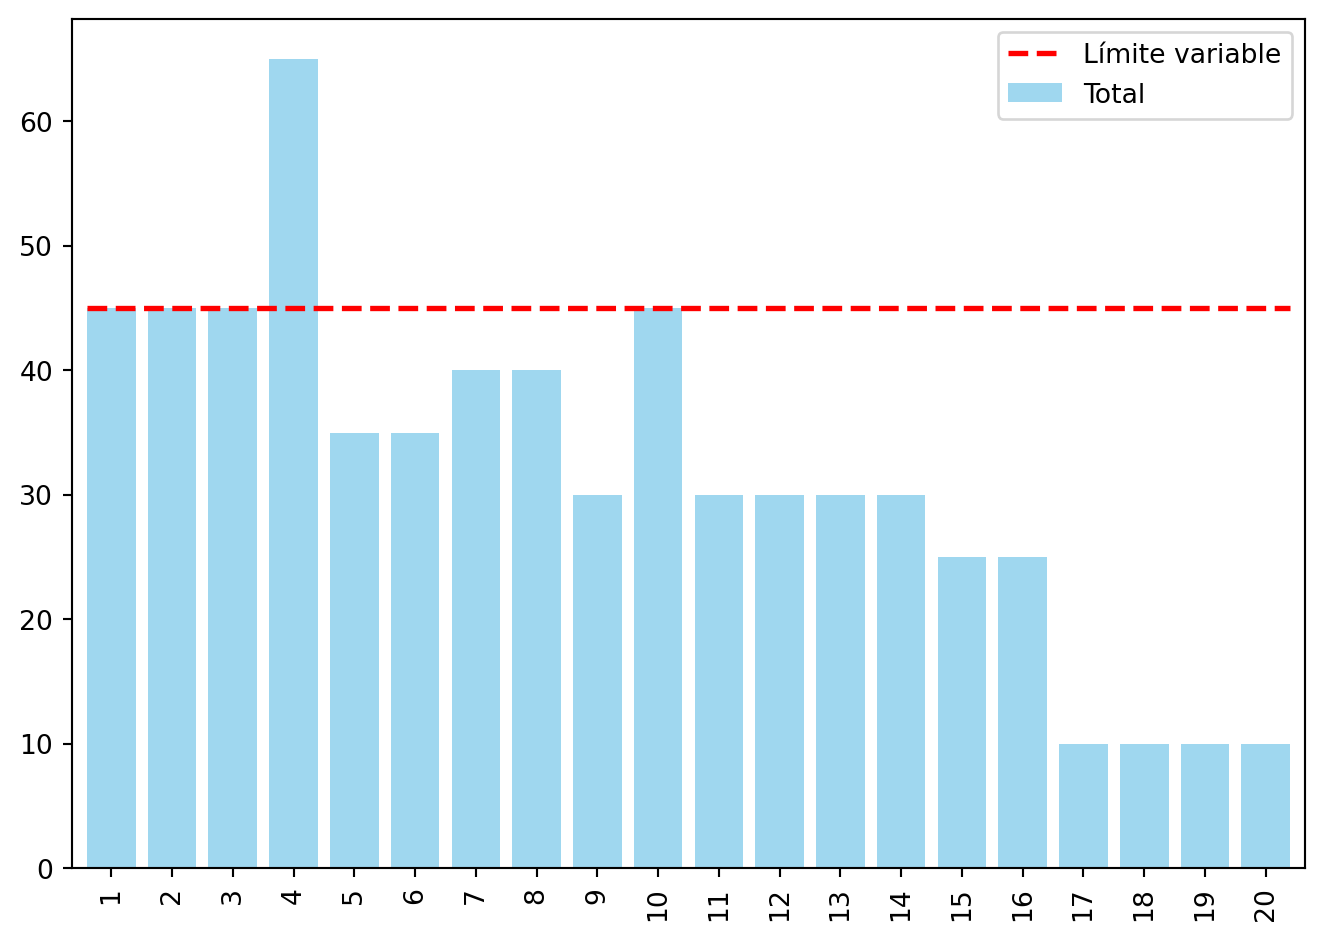

In [11]:
#| fig-cap: "Diagrama de cargas eléctricas frente a la capacidad de la acometida"
#| label: fig-cargas
cargas = gantt_inicial.data.loc['Total'].drop('H_total').astype(float)
plot_cargas(gantt_df=gantt_inicial, limite_maximo_recursos=[capacidad_acometida])

In [12]:
#| tbl-cap: "Desplazamientos de la nivelación"
#| label: tbl-nivelacion
proyecto_nivelado = proyecto.copy()
desplazamientos, cuadrados, datos_nivelados, gantt_nivelado, dibujo_niv = proyecto_nivelado.nivelar(
    data=datos_proyecto.copy(), duration_label='duration', resource_label='kW')
cargas_niveladas = gantt_nivelado.data.loc['Total'].drop('H_total').astype(float)
desplazamientos[desplazamientos['desplazamientos'] > 0]

,desplazamientos
D,3
H,5


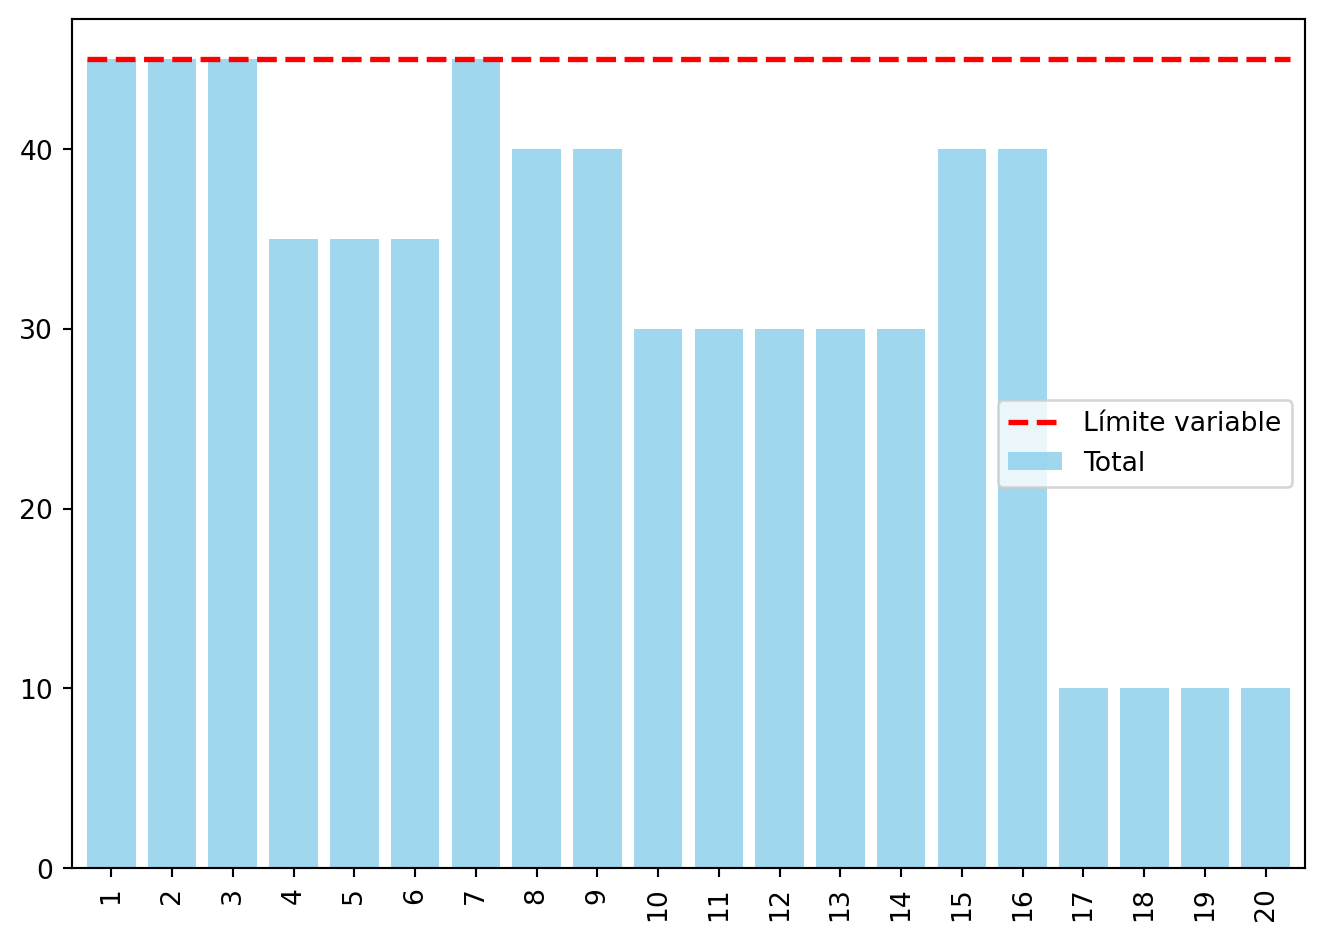

In [13]:
#| fig-cap: "Diagrama de cargas eléctricas tras la nivelación"
#| label: fig-cargasNivelado
plot_cargas(gantt_df=gantt_nivelado, limite_maximo_recursos=[capacidad_acometida])

In [14]:
energia = float(cargas.sum()) * horas_semana
Markdown(f'''Pico de **{int(cargas.max())} kW** con inicios más tempranos y **{int(cargas_niveladas.max())} kW** tras nivelar''' + (' (cabe en la acometida)' if cargas_niveladas.max() <= capacidad_acometida else ' (no cabe)') + f''', con la misma duración ({duracion} semanas). Energía de la obra: {energia:,.0f} kWh (la nivelación mueve la demanda, no la cambia).''')

Pico de **65 kW** con inicios más tempranos y **45 kW** tras nivelar (cabe en la acometida), con la misma duración (20 semanas). Energía de la obra: 25,400 kWh (la nivelación mueve la demanda, no la cambia).

## Apartado 2

In [15]:
display(Markdown(pregunta_2))

2. (A) Calcule el coste y las emisiones de las dos opciones: grupo electrógeno toda la obra, y grupo durante las 5 primeras semanas y acometida después (con las cargas niveladas). Compare el coste total al precio sombra.  

In [16]:
energia_inicial = float(cargas_niveladas.iloc[:plazo_acometida].sum()) * horas_semana
def opcion(semanas_grupo, kwh_grupo, kwh_red, acometida):
    litros = kwh_grupo * consumo_grupo
    coste = semanas_grupo * alquiler_grupo + litros * precio_gasoleo / 1000 + acometida + kwh_red * precio_red / 1000
    emisiones = (litros * factor_gasoleo + kwh_red * factor_red) / 1000
    return pd.Series({'alquiler del grupo (k€)': semanas_grupo * alquiler_grupo, 'gasóleo (litros)': litros,
                      'gasóleo (k€)': litros * precio_gasoleo / 1000, 'acometida (k€)': acometida, 'electricidad de red (k€)': kwh_red * precio_red / 1000,
                      'coste (k€)': coste, 'emisiones alcance 1 (t)': litros * factor_gasoleo / 1000, 'emisiones alcance 2 (t)': kwh_red * factor_red / 1000,
                      'emisiones (t CO₂)': emisiones, 'coste total al precio sombra (k€)': coste + emisiones * precio_sombra / 1000})
comparacion = pd.DataFrame({'grupo toda la obra': opcion(duracion, energia, 0, 0),
                            f'grupo {plazo_acometida} semanas + acometida': opcion(plazo_acometida, energia_inicial, energia - energia_inicial, coste_acometida)})
display(comparacion.round(2))
Markdown(f'''La opción mixta cuesta **{comparacion.iloc[5, 0] - comparacion.iloc[5, 1]:.1f} k€ menos** y emite **{comparacion.iloc[8, 0] - comparacion.iloc[8, 1]:.1f} t menos**; al precio sombra la diferencia total es de {comparacion.iloc[9, 0] - comparacion.iloc[9, 1]:.1f} k€.''')

,grupo toda la obra,grupo 5 semanas + acometida
alquiler del grupo (k€),16.00,4.00
gasóleo (litros),7620.00,2460.00
gasóleo (k€),9.91,3.20
acometida (k€),0.00,8.00
electricidad de red (k€),0.00,3.10
coste (k€),25.91,18.29
emisiones alcance 1 (t),18.82,6.08
emisiones alcance 2 (t),0.00,2.58
emisiones (t CO₂),18.82,8.66
coste total al precio sombra (k€),30.61,20.46


La opción mixta cuesta **7.6 k€ menos** y emite **10.2 t menos**; al precio sombra la diferencia total es de 10.2 k€.

## Apartado 3

In [17]:
display(Markdown(pregunta_3))

3. (B) Según los criterios de referencia, ¿qué opción es la correcta y en qué escalón de la pirámide está cada una? ¿A qué alcance pertenecen las emisiones del grupo electrógeno y las de la acometida?  

**S2.** Con el precio sombra la opción correcta es la de menor coste total: grupo las 5 primeras semanas y acometida después (20.5 k€ frente a 30.6); aquí ni siquiera hace falta el precio, porque también es más barata en dinero (18.3 frente a 25.9 k€). El argumento del pico (65 kW) desaparece al nivelar: el pico nivelado es 45 kW y cabe. **S1.** El grupo para toda la obra ni siquiera compensa; la opción mixta **minimiza** (10.2 t menos); **evitar** sería pedir la acometida con la antelación suficiente para no necesitar el grupo. **S6.** El gasóleo del grupo es **alcance 1** (fuente controlada por la obra, aunque se alquile); la electricidad de la acometida es **alcance 2**. Que el gasóleo «vaya a costes generales» no cambia el alcance ni la cuenta.

In [18]:
preguntas_test = [
    ('Las emisiones del gasóleo de un grupo electrógeno alquilado en la obra son…', ['alcance 1', 'alcance 2', 'alcance 3', 'del arrendador'],
     'S6: fuente controlada por la organización.'),
    ('Nivelar las cargas eléctricas dentro de las holguras…', ['reduce el pico de potencia sin cambiar la energía ni la duración', 'reduce la energía consumida', 'alarga el proyecto', 'cambia las duraciones'],
     'Lección 11: la nivelación mueve actividades no críticas.'),
    ('Con un precio sombra fijado, entre dos formas de suministro se elige…', ['la de menor coste total (dinero más emisiones al precio sombra)', 'la de menor alquiler', 'la que pida el jefe de obra', 'la de menos trámites'],
     'S2.'),
]
import os
def a_gift(preguntas_test, titulo, semilla=1):
    r = np.random.default_rng(semilla)
    lineas = [f'$CATEGORY: {titulo}', '']
    for i, (q, ops, fb) in enumerate(preguntas_test, 1):
        correcta = ops[0]
        todas = [ops[j] for j in r.permutation(len(ops))]
        cuerpo = ' '.join((f'={v}' if v == correcta else f'~{v}') for v in todas)
        lineas.append(f'::{titulo} P{i}::{q} {{{cuerpo} ####{fb}}}')
        lineas.append('')
    return '\n'.join(lineas)
gift = a_gift(preguntas_test, 'Sostenibilidad 20 — energía en obra')
os.makedirs(os.path.expanduser('~/temp'), exist_ok=True)
with open(os.path.expanduser('~/temp/cuestionario_sostenibilidad.gift'), 'w', encoding='utf8') as f:
    f.write(gift)
from pmule import muestra_test
muestra_test(preguntas_test)

$CATEGORY: Sostenibilidad 20 — energía en obra

::Sostenibilidad 20 — energía en obra P1::Las emisiones del gasóleo de un grupo electrógeno alquilado en la obra son… {=alcance 1 ~alcance 2 ~alcance 3 ~del arrendador ####S6: fuente controlada por la organización.}

::Sostenibilidad 20 — energía en obra P2::Nivelar las cargas eléctricas dentro de las holguras… {~cambia las duraciones =reduce el pico de potencia sin cambiar la energía ni la duración ~alarga el proyecto ~reduce la energía consumida ####Lección 11: la nivelación mueve actividades no críticas.}

::Sostenibilidad 20 — energía en obra P3::Con un precio sombra fijado, entre dos formas de suministro se elige… {~la de menos trámites =la de menor coste total (dinero más emisiones al precio sombra) ~la de menor alquiler ~la que pida el jefe de obra ####S2.}



## Apartado 4

In [19]:
display(Markdown(pregunta_4))

4. (C) ¿Qué propone al jefe de obra? Aplique la rúbrica de la lección.  

La pregunta del bloque C es abierta: no tiene una respuesta única y se evalúa el **procedimiento**: (1) identificar a todos los afectados, incluidos los que no están en la mesa (la comunidad, los trabajadores de la cadena, quien opere o desmantele lo construido, las generaciones siguientes) y qué pierde o gana cada uno con las cifras del bloque A; (2) formular al menos dos alternativas además de la propuesta, situándolas en la pirámide (compensar, restaurar, minimizar, evitar); (3) someter cada alternativa a tres pruebas —legalidad (¿cumple la norma?), publicidad (¿la defendería ante el inspector, el cliente o la prensa?) y ciclo de vida (¿quién paga el impacto y cuándo?)—; (4) decidir y redactar la comunicación con las cifras. Una respuesta que sólo opina, sin cifras ni alternativas, no supera la rúbrica.

Al jefe de obra: pedir la acometida hoy, nivelar las cargas (tabla del apartado 1) y alquilar el grupo sólo 5 semanas; cifras del apartado 2. Si el pico nivelado no cupiera en la acometida, la alternativa sería un grupo pequeño de apoyo en las semanas de pico, no uno grande toda la obra. Prueba de publicidad: ¿pondría en la memoria de sostenibilidad del proyecto 19 t de gasóleo pudiendo haber emitido 9?